# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset from the workspace folder.
df = pd.read_csv("car_purchase_data.csv")
df.head()

,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


### Step 2: Split features and target

In [2]:
# Use only the two features required by the assignment.
X = df[["Age", "Salary"]]
y = df["Purchased"]

print(f"Features: {list(X.columns)}")
print(f"Target classes: {sorted(y.unique())}")

Features: ['Age', 'Salary']
Target classes: [np.int64(0), np.int64(1)]


### Step 3: Train/Test Split

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")

Training rows: 300
Testing rows: 100


### Step 4: Feature Scaling

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training features scaled; test features transformed using training-set statistics.")

Training features scaled; test features transformed using training-set statistics.


### Step 5: Train Logistic Regression Model

In [14]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

print("Logistic regression model trained.")

Logistic regression model trained.


### Step 6: Predict and Evaluate

In [15]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict both class labels and purchase probabilities for the test set.
y_pred = model.predict(X_test_scaled)
y_probability = model.predict_proba(X_test_scaled)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Not purchased", "Purchased"], zero_division=0))

Accuracy: 0.860
Confusion matrix (rows = actual, columns = predicted):
[[61  2]
 [12 25]]

Classification report:
               precision    recall  f1-score   support

Not purchased       0.84      0.97      0.90        63
    Purchased       0.93      0.68      0.78        37

     accuracy                           0.86       100
    macro avg       0.88      0.82      0.84       100
 weighted avg       0.87      0.86      0.85       100



### Step 7: Visualization of Decision Regions

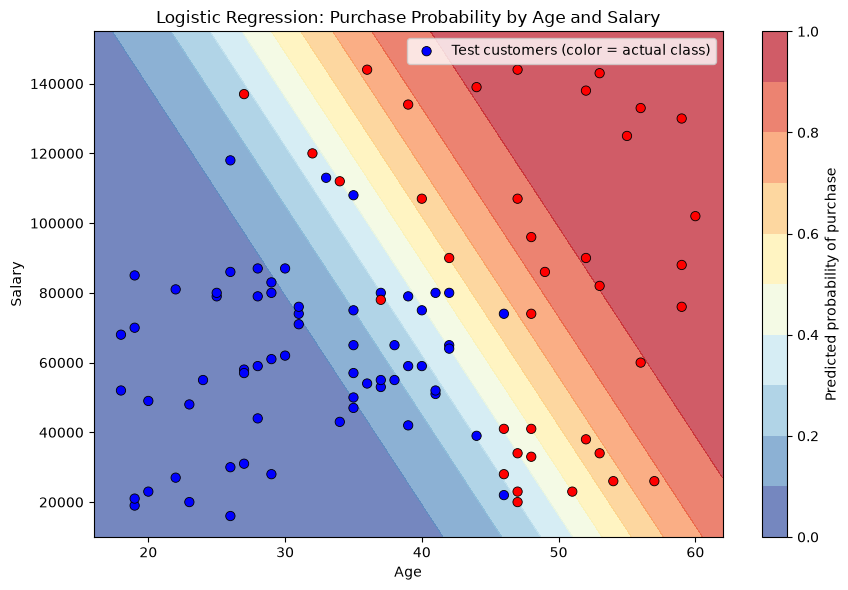

In [16]:
import numpy as np

# Build a grid in the original units, then apply the fitted scaler and model.
age_min, age_max = X["Age"].min() - 2, X["Age"].max() + 2
salary_min, salary_max = X["Salary"].min() - 5000, X["Salary"].max() + 5000
age_grid, salary_grid = np.meshgrid(
    np.linspace(age_min, age_max, 300),
    np.linspace(salary_min, salary_max, 300),
)
grid = pd.DataFrame({"Age": age_grid.ravel(), "Salary": salary_grid.ravel()})
purchase_probability_grid = model.predict_proba(scaler.transform(grid))[:, 1]
purchase_probability_grid = purchase_probability_grid.reshape(age_grid.shape)

plt.figure(figsize=(9, 6))
contour = plt.contourf(
    age_grid,
    salary_grid,
    purchase_probability_grid,
    levels=np.linspace(0, 1, 11),
    cmap="RdYlBu_r",
    alpha=0.7,
)
plt.colorbar(contour, label="Predicted probability of purchase")
points = plt.scatter(
    X_test["Age"],
    X_test["Salary"],
    c=y_test,
    cmap="bwr",
    edgecolor="black",
    linewidth=0.6,
    s=45,
    label="Test customers (color = actual class)",
)
plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Logistic Regression: Purchase Probability by Age and Salary")
plt.legend(handles=[points], loc="best")
plt.tight_layout()
plt.show()

## IV. Reflection Questions 
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


1. **Why can logistic regression classify if it outputs probabilities?** It estimates the probability of class 1. A decision threshold, usually 0.5, converts that probability into a class: probabilities at or above the threshold predict a purchase, and lower probabilities predict no purchase. The threshold can be adjusted when false positives and false negatives have different costs.

2. **Which customers are more likely to purchase?** The model estimates purchase likelihood from age and salary together. The probability plot shows higher predicted purchase probabilities toward older ages and higher salaries, although the model's prediction depends on both features and is not a guarantee for any individual customer.

3. **What could cause low accuracy in this task?** This run achieved 86% accuracy, below the rubric's 87.5% target. It correctly identified 25 of 37 purchasers (recall about 0.68), while missing 12 purchasers and incorrectly flagging 2 non-purchasers. Age and salary alone may not explain all decisions; overlapping customer groups, noisy labels, limited data, and the particular train/test split can also affect results. Accuracy alone may hide errors on a class, so the confusion matrix and class-specific precision/recall are useful too.

4. **What might improve accuracy?** Add relevant information such as credit score, savings, vehicle needs, location, or prior purchase history; collect more representative observations; check for missing values and unusual values; compare other models and tune the decision threshold using cross-validation. Any additional features must be available at prediction time and should be evaluated on data not used for training.